In [1]:
#
# Importación de los datos
#
import pandas as pd  #  type: ignore

df = pd.read_csv("../data/mtcars.csv")
df.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


In [2]:
# Tamaño del dataset

df.shape


(32, 11)

In [3]:
df.isnull().sum()

mpg     0
cyl     0
disp    0
hp      0
drat    0
wt      0
qsec    0
vs      0
am      0
gear    0
carb    0
dtype: int64

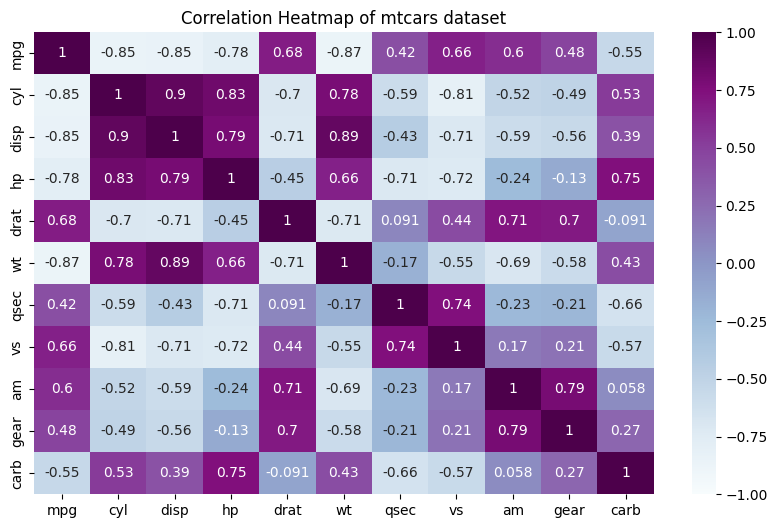

In [ ]:
#
# Correlación entre variables
#
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(
    corr,
    xticklabels=corr.columns.values,
    yticklabels=corr.columns.values,
    cmap="BuPu",
    vmin=-1,
    vmax=1,
    annot=True,
)
plt.title("Correlation Heatmap of mtcars dataset")
plt.show()

# Se busca la correlación menos influyente entre las variables, para eliminarla del dataset y mejorar el modelo de predicción.

In [6]:
#
# Particionamiento de los datos
#
from sklearn.model_selection import train_test_split

features = df.columns[1:]
target = df.columns[0]
X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
#
# Tipo de las columnas
#
df.dtypes


mpg     float64
cyl       int64
disp    float64
hp        int64
drat    float64
wt      float64
qsec    float64
vs        int64
am        int64
gear      int64
carb      int64
dtype: object

In [ ]:
#
# Modelado
#
from sklearn.preprocessing import StandardScaler # se incorpora para transformar los datos y mejorar el rendimiento del modelo (Normalización de los datos)
from sklearn.pipeline import Pipeline #  Para crear un pipeline que permita encadenar varias transformaciones y el modelo de regresión lineal en un solo objeto.
from sklearn.linear_model import Lasso # Para crear un modelo de regresión lineal con regularización Lasso (L1) que permite seleccionar las variables más importantes y reducir el sobreajuste.
from sklearn.metrics import r2_score, mean_squared_error

pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("lasso", Lasso(max_iter=10000)),  # alpha=1.0
    ]
)

pipeline.fit(X_train, y_train)

y_train_pred = pipeline.predict(X_train)
y_test_pred = pipeline.predict(X_test)


rsquared_train = r2_score(y_train, y_train_pred)
rsquared_test = r2_score(y_test, y_test_pred)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)


print(f"Mean Squared Error:    {mse_train:0.2f} ({mse_test:0.2f})")
print(f"         R-squared: {rsquared_train:6.5f} ({rsquared_test:6.5f})")

Mean Squared Error:    6.28 (9.26)
         R-squared: 0.81430 (0.76829)


Text(0.5, 1.0, 'Coefficient values with increasing values of alpha')

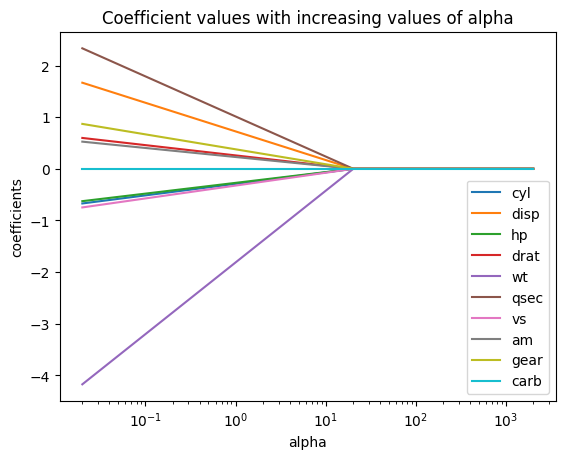

In [ ]:
#
# Análisis del alpha
#
import numpy as np

coeff = pd.Series(pipeline["lasso"].coef_, index=features)

alphas = np.linspace(0.01, 1000, 100) # 100 valores de alpha entre 0.01 y 1000
coefs = []

for a in alphas: # 
    pipeline["lasso"].set_params(alpha=a) # Laso penaliza los coeficientes de las variables, y a medida que aumenta el valor de alpha, los coeficientes se acercan a cero, lo que indica que la variable es menos importante para el modelo.
    pipeline.fit(X_train, y_train)
    coefs.append(pipeline["lasso"].coef_)

ax = plt.gca()
ax.plot(alphas * 2, coefs)
ax.set_xscale("log")
ax.legend(features)
ax.grid(False)
plt.axis("tight")
plt.xlabel("alpha")
plt.ylabel("coefficients")
plt.title("Coefficient values with increasing values of alpha")

In [ ]:
# Búsqueda de hiperparámetros

from sklearn.model_selection import GridSearchCV

alphas = {"lasso__alpha": np.linspace(0.01, 2.0, 100)}

grid_search = GridSearchCV(
    pipeline,
    alphas,
    scoring="neg_mean_squared_error",
    cv=10,
)

grid_search.fit(X_train, y_train)

y_train_pred = grid_search.predict(X_train)
y_test_pred = grid_search.predict(X_test)

rsquared_train = r2_score(y_train, y_train_pred)
rsquared_test = r2_score(y_test, y_test_pred)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

print(f"     Best value for lambda : ", grid_search.best_params_)
print("Best score for cost function: ", grid_search.best_score_)
print()
print(f"Mean Squared Error:    {mse_train:0.2f} ({mse_test:0.2f})") 
print(f"         R-squared: {rsquared_train:6.5f} ({rsquared_test:6.5f})") # El R2 no es el mejor indicador para evaluar la calidad del modelo, ya que puede ser engañoso en algunos casos. Por ejemplo, un modelo con un R2 alto puede tener un error cuadrático medio (MSE) alto, lo que indica que el modelo no está prediciendo bien los valores. Por lo tanto, es importante considerar tanto el R2 como el MSE al evaluar la calidad del modelo.

     Best value for lambda :  {'lasso__alpha': 0.7336363636363636}
Best score for cost function:  -10.056452117669208

Mean Squared Error:    5.73 (8.46)
         R-squared: 0.83046 (0.78832)


In [11]:
#
# Salva el modelo
#
import pickle
import os


with open("../submission/estimator.pkl", "wb") as f:
    pickle.dump(grid_search, f)
